<a href="https://colab.research.google.com/github/RiyaSunil28/nitinternship/blob/main/Week6_nit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q open_clip_torch ftfy timm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.7 MB/s eta 0:00:00


In [ ]:
import os
import shutil

import torch
import torch.nn as nn
import torch.optim as optim

import open_clip
import timm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import roc_auc_score, roc_curve

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

Using device: cuda


In [ ]:
def fpr_at_95_tpr(labels, scores):

    fpr, tpr, _ = roc_curve(labels, scores)

    return fpr[np.argmax(tpr >= 0.95)]


def oscr(known_scores, known_correct, unknown_scores):

    correct_scores = np.sort(known_scores[known_correct])

    unknown_sorted = np.sort(unknown_scores)

    thresholds = np.sort(np.concatenate([
        known_scores,
        unknown_scores
    ]))

    ccr = (
        len(correct_scores)
        - np.searchsorted(correct_scores, thresholds, side="right")
    ) / len(known_scores)

    fpr = (
        len(unknown_sorted)
        - np.searchsorted(unknown_sorted, thresholds, side="right")
    ) / len(unknown_scores)

    order = np.argsort(fpr)

    trapezoid = getattr(np, "trapezoid", None) or np.trapz

    return trapezoid(ccr[order], fpr[order])


def compute_metrics(known_scores, unknown_scores, known_correct):

    labels = np.concatenate([
        np.ones(len(known_scores)),
        np.zeros(len(unknown_scores))
    ])

    scores = np.concatenate([
        known_scores,
        unknown_scores
    ])

    return {
        "AUROC": round(roc_auc_score(labels, scores), 4),
        "FPR@95TPR": round(fpr_at_95_tpr(labels, scores), 4),
        "OSCR": round(
            oscr(known_scores, known_correct, unknown_scores),
            4
        )
    }

In [ ]:
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai"
)

tokenizer = open_clip.get_tokenizer("ViT-B-32")

clip_model = clip_model.to(device)
clip_model.eval()

for param in clip_model.parameters():
    param.requires_grad = False

logit_scale = clip_model.logit_scale.exp().detach()

print("CLIP loaded and frozen")

open_clip_model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP loaded and frozen


In [ ]:
vit_model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=True
)

vit_model = vit_model.to(device)
vit_model.eval()

for param in vit_model.parameters():
    param.requires_grad = False

vit_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("ViT loaded and frozen")

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

ViT loaded and frozen


In [ ]:
def extract_clip_features(dataset, indices=None):

    if indices is not None:
        dataset = Subset(dataset, indices)

    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False,
        num_workers=2
    )

    all_features = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            features = clip_model.encode_image(images.to(device))

            features = features / features.norm(
                dim=-1,
                keepdim=True
            )

            all_features.append(features.cpu())
            all_labels.append(labels)

    return torch.cat(all_features), torch.cat(all_labels)


def extract_vit_features(dataset, indices=None):

    if indices is not None:
        dataset = Subset(dataset, indices)

    loader = DataLoader(
        dataset,
        batch_size=128,
        shuffle=False,
        num_workers=2
    )

    all_features = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            features = vit_model.forward_features(images.to(device))

            cls_features = features[:, 0]

            all_features.append(cls_features.cpu())
            all_labels.append(labels)

    return torch.cat(all_features), torch.cat(all_labels)

In [ ]:
def train_linear_probe(features, targets, num_classes, epochs=10):

    probe = nn.Linear(features.shape[1], num_classes).to(device)

    optimizer = optim.Adam(probe.parameters(), lr=1e-3)

    criterion = nn.CrossEntropyLoss()

    features = features.to(device)
    targets = targets.to(device)

    batch_size = 512

    for epoch in range(epochs):

        perm = torch.randperm(features.shape[0])

        for start in range(0, len(perm), batch_size):

            batch_idx = perm[start:start + batch_size]

            logits = probe(features[batch_idx])

            loss = criterion(logits, targets[batch_idx])

            optimizer.zero_grad()

            loss.backward()

            optimizer.step()

    return probe


def train_prompt_vectors(image_features, targets, text_features, epochs=10):

    prompt_vectors = nn.Parameter(
        torch.randn(
            text_features.shape[0],
            text_features.shape[1],
            device=device
        ) * 0.01
    )

    optimizer = optim.Adam([prompt_vectors], lr=1e-3)

    criterion = nn.CrossEntropyLoss()

    image_features = image_features.to(device)
    targets = targets.to(device)

    batch_size = 512

    for epoch in range(epochs):

        perm = torch.randperm(image_features.shape[0])

        for start in range(0, len(perm), batch_size):

            batch_idx = perm[start:start + batch_size]

            adapted_text = text_features + prompt_vectors

            adapted_text = adapted_text / adapted_text.norm(
                dim=-1,
                keepdim=True
            )

            logits = logit_scale * image_features[batch_idx] @ adapted_text.T

            loss = criterion(logits, targets[batch_idx])

            optimizer.zero_grad()

            loss.backward()

            optimizer.step()

    with torch.no_grad():

        tuned_text = text_features + prompt_vectors

        tuned_text = tuned_text / tuned_text.norm(
            dim=-1,
            keepdim=True
        )

    return tuned_text

In [ ]:
def fusion_scores(image_features, tuned_text, centroids):

    image_features = image_features.to(device)

    with torch.no_grad():

        similarities = image_features @ tuned_text.T

        logits = logit_scale * similarities

        energy = torch.logsumexp(logits, dim=1)

        top2 = similarities.topk(2, dim=1).values

        margin = top2[:, 0] - top2[:, 1]

        centroid_similarity = (
            image_features @ centroids.T
        ).max(dim=1).values

        predictions = similarities.argmax(dim=1).cpu()

    return (
        energy.cpu().numpy(),
        margin.cpu().numpy(),
        centroid_similarity.cpu().numpy(),
        predictions
    )


def tune_fusion_weights(val_known_norm, val_unknown_norm):

    weight_values = [0.0, 0.25, 0.5, 0.75, 1.0]

    best_weights = None
    best_auroc = 0

    for a, b, c in product(weight_values, repeat=3):

        if a + b + c == 0:
            continue

        total = a + b + c

        weights = (a / total, b / total, c / total)

        known = sum(
            w * s for w, s in zip(weights, val_known_norm)
        )

        unknown = sum(
            w * s for w, s in zip(weights, val_unknown_norm)
        )

        labels = np.concatenate([
            np.ones(len(known)),
            np.zeros(len(unknown))
        ])

        auroc = roc_auc_score(
            labels,
            np.concatenate([known, unknown])
        )

        if auroc > best_auroc:
            best_auroc = auroc
            best_weights = weights

    return best_weights

In [ ]:
def evaluate_dataset(
    dataset_name,
    train_clip_features, train_labels,
    train_vit_features,
    test_clip_features, test_vit_features, test_labels,
    known_classes, known_names,
    proxy_unknown_features
):

    rows = []

    known_mask = torch.isin(
        test_labels,
        torch.tensor(known_classes)
    )

    remap = {c: i for i, c in enumerate(known_classes)}

    train_targets = torch.tensor([
        remap[int(l)] for l in train_labels
    ])

    test_known_targets = torch.tensor([
        remap[int(l)] for l in test_labels[known_mask]
    ])

    print(f"[{dataset_name}]",
          "known test:", int(known_mask.sum()),
          "| unknown test:", int((~known_mask).sum()))

    # ------------------------------------------------------------
    # Method 1: ViT baseline + linear probe (MSP and Energy)
    # ------------------------------------------------------------

    probe = train_linear_probe(
        train_vit_features,
        train_targets,
        len(known_classes)
    )

    with torch.no_grad():

        known_logits = probe(
            test_vit_features[known_mask].to(device)
        )

        unknown_logits = probe(
            test_vit_features[~known_mask].to(device)
        )

    vit_correct = (
        known_logits.argmax(dim=1).cpu() == test_known_targets
    ).numpy()

    known_msp = torch.softmax(known_logits, dim=1).max(dim=1).values
    unknown_msp = torch.softmax(unknown_logits, dim=1).max(dim=1).values

    known_energy = torch.logsumexp(known_logits, dim=1)
    unknown_energy = torch.logsumexp(unknown_logits, dim=1)

    rows.append({
        "Dataset": dataset_name,
        "Method": "ViT + MSP",
        **compute_metrics(
            known_msp.cpu().numpy(),
            unknown_msp.cpu().numpy(),
            vit_correct
        )
    })

    rows.append({
        "Dataset": dataset_name,
        "Method": "ViT + Energy",
        **compute_metrics(
            known_energy.cpu().numpy(),
            unknown_energy.cpu().numpy(),
            vit_correct
        )
    })

    # ------------------------------------------------------------
    # Method 2: CLIP zero-shot (Similarity and Entropy)
    # ------------------------------------------------------------

    prompts = [
        f"a photo of a {name}"
        for name in known_names
    ]

    text_tokens = tokenizer(prompts).to(device)

    with torch.no_grad():

        text_features = clip_model.encode_text(text_tokens)

        text_features = text_features / text_features.norm(
            dim=-1,
            keepdim=True
        )

    def clip_zero_shot_scores(image_features):

        with torch.no_grad():

            similarities = image_features.to(device) @ text_features.T

            probabilities = torch.softmax(similarities, dim=1)

            max_similarity = similarities.max(dim=1).values

            entropy = -(
                probabilities * torch.log(probabilities + 1e-12)
            ).sum(dim=1)

            predictions = similarities.argmax(dim=1).cpu()

        return (
            max_similarity.cpu().numpy(),
            entropy.cpu().numpy(),
            predictions
        )

    known_sim, known_ent, known_preds = clip_zero_shot_scores(
        test_clip_features[known_mask]
    )

    unknown_sim, unknown_ent, _ = clip_zero_shot_scores(
        test_clip_features[~known_mask]
    )

    clip_correct = (known_preds == test_known_targets).numpy()

    rows.append({
        "Dataset": dataset_name,
        "Method": "CLIP + Similarity",
        **compute_metrics(known_sim, unknown_sim, clip_correct)
    })

    rows.append({
        "Dataset": dataset_name,
        "Method": "CLIP + Entropy",
        **compute_metrics(-known_ent, -unknown_ent, clip_correct)
    })

    # ------------------------------------------------------------
    # Method 3: Prompt-Tuned CLIP + Fused Score (proposed)
    # ------------------------------------------------------------

    generator = torch.Generator().manual_seed(42)

    perm = torch.randperm(
        train_clip_features.shape[0],
        generator=generator
    )

    split = int(0.8 * len(perm))

    fit_idx = perm[:split]
    val_idx = perm[split:]

    fit_features = train_clip_features[fit_idx]
    fit_targets = train_targets[fit_idx]

    val_known_features = train_clip_features[val_idx]

    tuned_text = train_prompt_vectors(
        fit_features,
        fit_targets,
        text_features
    )

    centroids = []

    for class_idx in range(len(known_classes)):

        class_features = fit_features[fit_targets == class_idx]

        centroid = class_features.mean(dim=0)

        centroid = centroid / centroid.norm()

        centroids.append(centroid)

    centroids = torch.stack(centroids).to(device)

    val_known_raw = fusion_scores(
        val_known_features, tuned_text, centroids
    )[:3]

    val_unknown_raw = fusion_scores(
        proxy_unknown_features, tuned_text, centroids
    )[:3]

    means = [s.mean() for s in val_known_raw]
    stds = [s.std() for s in val_known_raw]

    def normalize(raw):
        return [
            (raw[i] - means[i]) / stds[i]
            for i in range(3)
        ]

    best_weights = tune_fusion_weights(
        normalize(val_known_raw),
        normalize(val_unknown_raw)
    )

    print(f"[{dataset_name}] fusion weights:",
          tuple(round(w, 3) for w in best_weights))

    known_raw = fusion_scores(
        test_clip_features[known_mask], tuned_text, centroids
    )

    unknown_raw = fusion_scores(
        test_clip_features[~known_mask], tuned_text, centroids
    )

    fused_correct = (known_raw[3] == test_known_targets).numpy()

    known_norm = normalize(known_raw[:3])
    unknown_norm = normalize(unknown_raw[:3])

    known_fused = sum(
        w * s for w, s in zip(best_weights, known_norm)
    )

    unknown_fused = sum(
        w * s for w, s in zip(best_weights, unknown_norm)
    )

    rows.append({
        "Dataset": dataset_name,
        "Method": "Prompt CLIP + Fused (ours)",
        **compute_metrics(known_fused, unknown_fused, fused_correct)
    })

    return pd.DataFrame(rows)

In [ ]:
!mkdir -p data
!rm -f data/cifar-10-python.tar.gz data/cifar-100-python.tar.gz
!wget -q https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz -P data
!wget -q https://data.brainchip.com/dataset-mirror/cifar100/cifar-100-python.tar.gz -P data
!ls -lh data

total 324M
-rw-r--r-- 1 root root 162M Jul  7  2022 cifar-100-python.tar.gz
-rw-r--r-- 1 root root 163M Jul  7  2022 cifar-10-python.tar.gz


In [ ]:
cifar10_train_clip = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=clip_preprocess
)

cifar10_test_clip = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=clip_preprocess
)

cifar10_train_vit = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=vit_transform
)

cifar10_test_vit = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=vit_transform
)

In [ ]:
cifar10_known = [0, 1, 3, 5, 7]

cifar10_known_names = [
    cifar10_test_clip.classes[i]
    for i in cifar10_known
]

cifar10_train_indices = [
    i for i, label in enumerate(cifar10_train_clip.targets)
    if label in cifar10_known
]

print("Known classes:", cifar10_known_names)
print("Known train samples:", len(cifar10_train_indices))

Known classes: ['airplane', 'automobile', 'cat', 'dog', 'horse']
Known train samples: 25000


In [ ]:
c10_train_clip_features, c10_train_labels = extract_clip_features(
    cifar10_train_clip,
    cifar10_train_indices
)

c10_train_vit_features, _ = extract_vit_features(
    cifar10_train_vit,
    cifar10_train_indices
)

c10_test_clip_features, c10_test_labels = extract_clip_features(
    cifar10_test_clip
)

c10_test_vit_features, _ = extract_vit_features(
    cifar10_test_vit
)

print("CIFAR-10 features ready")

CIFAR-10 features ready


In [ ]:
cifar100_train_clip = datasets.CIFAR100(
    root="./data",
    train=True,
    download=True,
    transform=clip_preprocess
)

cifar100_test_clip = datasets.CIFAR100(
    root="./data",
    train=False,
    download=True,
    transform=clip_preprocess
)

cifar100_train_vit = datasets.CIFAR100(
    root="./data",
    train=True,
    download=True,
    transform=vit_transform
)

cifar100_test_vit = datasets.CIFAR100(
    root="./data",
    train=False,
    download=True,
    transform=vit_transform
)

In [ ]:
cifar100_known = list(range(20))

cifar100_known_names = [
    cifar100_test_clip.classes[i].replace("_", " ")
    for i in cifar100_known
]

cifar100_train_indices = [
    i for i, label in enumerate(cifar100_train_clip.targets)
    if label in cifar100_known
]

print("Known classes:", cifar100_known_names)
print("Known train samples:", len(cifar100_train_indices))

Known classes: ['apple', 'aquarium fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 'can', 'castle', 'caterpillar', 'cattle']
Known train samples: 10000


In [ ]:
c100_train_clip_features, c100_train_labels = extract_clip_features(
    cifar100_train_clip,
    cifar100_train_indices
)

c100_train_vit_features, _ = extract_vit_features(
    cifar100_train_vit,
    cifar100_train_indices
)

c100_test_clip_features, c100_test_labels = extract_clip_features(
    cifar100_test_clip
)

c100_test_vit_features, _ = extract_vit_features(
    cifar100_test_vit
)

print("CIFAR-100 features ready")

CIFAR-100 features ready


In [ ]:
!wget -q http://cs231n.stanford.edu/tiny-imagenet-200.zip
!unzip -q -o tiny-imagenet-200.zip

print("TinyImageNet downloaded")

TinyImageNet downloaded


In [ ]:
val_dir = "tiny-imagenet-200/val"

annotations_path = os.path.join(val_dir, "val_annotations.txt")

if os.path.exists(os.path.join(val_dir, "images")):

    with open(annotations_path) as f:

        for line in f:

            parts = line.strip().split("\t")

            image_name = parts[0]
            wnid = parts[1]

            class_dir = os.path.join(val_dir, wnid)

            os.makedirs(class_dir, exist_ok=True)

            source = os.path.join(val_dir, "images", image_name)

            if os.path.exists(source):
                shutil.move(
                    source,
                    os.path.join(class_dir, image_name)
                )

    shutil.rmtree(os.path.join(val_dir, "images"))

print("Validation folder reorganized")

Validation folder reorganized


In [ ]:
# TinyImageNet folders are WordNet ids (e.g. n01443537),
# so words.txt is used to get readable names for the CLIP prompts

wnid_to_name = {}

with open("tiny-imagenet-200/words.txt") as f:

    for line in f:

        wnid, names = line.strip().split("\t")

        wnid_to_name[wnid] = names.split(",")[0].lower()

tin_train_clip = datasets.ImageFolder(
    "tiny-imagenet-200/train",
    transform=clip_preprocess
)

tin_test_clip = datasets.ImageFolder(
    val_dir,
    transform=clip_preprocess
)

tin_train_vit = datasets.ImageFolder(
    "tiny-imagenet-200/train",
    transform=vit_transform
)

tin_test_vit = datasets.ImageFolder(
    val_dir,
    transform=vit_transform
)

print("Train classes:", len(tin_train_clip.classes))
print("Test classes:", len(tin_test_clip.classes))

Train classes: 200
Test classes: 200


In [ ]:
tin_known = list(range(20))

tin_known_names = [
    wnid_to_name[tin_test_clip.classes[i]]
    for i in tin_known
]

# training folder and validation folder can order classes differently,
# so training labels are converted to the validation class indexing

train_to_test = {
    train_idx: tin_test_clip.class_to_idx[wnid]
    for wnid, train_idx in tin_train_clip.class_to_idx.items()
}

tin_known_wnids = [tin_test_clip.classes[i] for i in tin_known]

tin_train_indices = [
    i for i, label in enumerate(tin_train_clip.targets)
    if train_to_test[label] in tin_known
]

print("Known classes:", tin_known_names)
print("Known train samples:", len(tin_train_indices))

Known classes: ['goldfish', 'european fire salamander', 'bullfrog', 'tailed frog', 'american alligator', 'boa constrictor', 'trilobite', 'scorpion', 'black widow', 'tarantula', 'centipede', 'goose', 'koala', 'jellyfish', 'brain coral', 'snail', 'slug', 'sea slug', 'american lobster', 'spiny lobster']
Known train samples: 10000


In [ ]:
tin_train_clip_features, tin_train_labels_raw = extract_clip_features(
    tin_train_clip,
    tin_train_indices
)

tin_train_vit_features, _ = extract_vit_features(
    tin_train_vit,
    tin_train_indices
)

tin_test_clip_features, tin_test_labels = extract_clip_features(
    tin_test_clip
)

tin_test_vit_features, _ = extract_vit_features(
    tin_test_vit
)

# convert training labels to the validation indexing

tin_train_labels = torch.tensor([
    train_to_test[int(l)] for l in tin_train_labels_raw
])

print("TinyImageNet features ready")

TinyImageNet features ready


In [ ]:
results_c10 = evaluate_dataset(
    "CIFAR-10",
    c10_train_clip_features, c10_train_labels,
    c10_train_vit_features,
    c10_test_clip_features, c10_test_vit_features, c10_test_labels,
    cifar10_known, cifar10_known_names,
    proxy_unknown_features=c100_test_clip_features[:5000]
)

results_c10

[CIFAR-10] known test: 5000 | unknown test: 5000
[CIFAR-10] fusion weights: (0.5, 0.25, 0.25)


,Dataset,Method,AUROC,FPR@95TPR,OSCR
0,CIFAR-10,ViT + MSP,0.9172,0.5482,0.8975
1,CIFAR-10,ViT + Energy,0.9575,0.2600,0.9253
2,CIFAR-10,CLIP + Similarity,0.9153,0.3616,0.8544
3,CIFAR-10,CLIP + Entropy,0.9205,0.4302,0.8624
4,CIFAR-10,Prompt CLIP + Fused (ours),0.9493,0.2706,0.9229


In [ ]:
results_c100 = evaluate_dataset(
    "CIFAR-100",
    c100_train_clip_features, c100_train_labels,
    c100_train_vit_features,
    c100_test_clip_features, c100_test_vit_features, c100_test_labels,
    cifar100_known, cifar100_known_names,
    proxy_unknown_features=c10_test_clip_features[:5000]
)

results_c100

[CIFAR-100] known test: 2000 | unknown test: 8000
[CIFAR-100] fusion weights: (0.75, 0.0, 0.25)


,Dataset,Method,AUROC,FPR@95TPR,OSCR
0,CIFAR-100,ViT + MSP,0.8852,0.5426,0.8485
1,CIFAR-100,ViT + Energy,0.9075,0.4632,0.8592
2,CIFAR-100,CLIP + Similarity,0.8232,0.7130,0.7185
3,CIFAR-100,CLIP + Entropy,0.7560,0.8094,0.6633
4,CIFAR-100,Prompt CLIP + Fused (ours),0.8767,0.5871,0.8222


In [ ]:
results_tin = evaluate_dataset(
    "TinyImageNet",
    tin_train_clip_features, tin_train_labels,
    tin_train_vit_features,
    tin_test_clip_features, tin_test_vit_features, tin_test_labels,
    tin_known, tin_known_names,
    proxy_unknown_features=c100_test_clip_features[:5000]
)

results_tin

[TinyImageNet] known test: 1000 | unknown test: 9000
[TinyImageNet] fusion weights: (0.0, 0.333, 0.667)


,Dataset,Method,AUROC,FPR@95TPR,OSCR
0,TinyImageNet,ViT + MSP,0.9527,0.3188,0.8592
1,TinyImageNet,ViT + Energy,0.9687,0.1968,0.8632
2,TinyImageNet,CLIP + Similarity,0.9357,0.2760,0.5774
3,TinyImageNet,CLIP + Entropy,0.8038,0.7630,0.5226
4,TinyImageNet,Prompt CLIP + Fused (ours),0.9339,0.2810,0.7492


In [ ]:
all_results = pd.concat(
    [results_c10, results_c100, results_tin],
    ignore_index=True
)

all_results

,Dataset,Method,AUROC,FPR@95TPR,OSCR
0,CIFAR-10,ViT + MSP,0.9172,0.5482,0.8975
1,CIFAR-10,ViT + Energy,0.9575,0.2600,0.9253
2,CIFAR-10,CLIP + Similarity,0.9153,0.3616,0.8544
3,CIFAR-10,CLIP + Entropy,0.9205,0.4302,0.8624
4,CIFAR-10,Prompt CLIP + Fused (ours),0.9493,0.2706,0.9229
5,CIFAR-100,ViT + MSP,0.8852,0.5426,0.8485
6,CIFAR-100,ViT + Energy,0.9075,0.4632,0.8592
7,CIFAR-100,CLIP + Similarity,0.8232,0.7130,0.7185
8,CIFAR-100,CLIP + Entropy,0.7560,0.8094,0.6633
9,CIFAR-100,Prompt CLIP + Fused (ours),0.8767,0.5871,0.8222


In [ ]:
auroc_table = all_results.pivot(
    index="Method",
    columns="Dataset",
    values="AUROC"
)

auroc_table

Dataset,CIFAR-10,CIFAR-100,TinyImageNet
Method,,,
CLIP + Entropy,0.9205,0.7560,0.8038
CLIP + Similarity,0.9153,0.8232,0.9357
Prompt CLIP + Fused (ours),0.9493,0.8767,0.9339
ViT + Energy,0.9575,0.9075,0.9687
ViT + MSP,0.9172,0.8852,0.9527


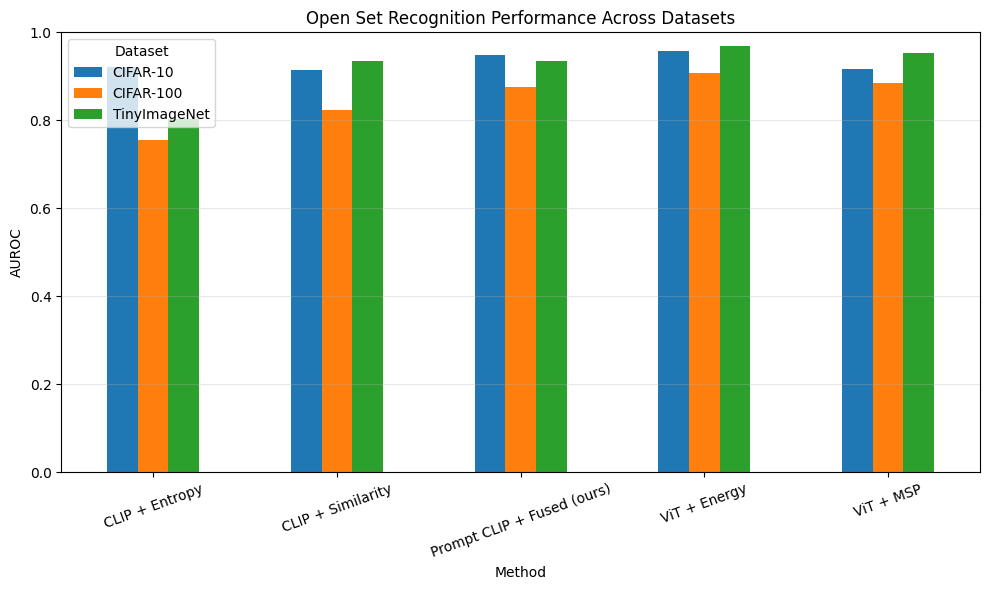

In [ ]:
auroc_table.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("AUROC")

plt.title("Open Set Recognition Performance Across Datasets")

plt.xticks(rotation=20)

plt.ylim(0, 1)

plt.legend(title="Dataset")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

In [ ]:
all_results.to_csv("week6_full_results.csv", index=False)

print("Saved: week6_full_results.csv")

Saved: week6_full_results.csv
